In [1]:
import numpy as np
import matplotlib.pyplot as plt
predata=np.loadtxt('data/train.csv', delimiter=',', skiprows=1)


In [2]:
np.save("data/train.npy", predata)

In [3]:
data=np.load("data/train.npy")

In [4]:
print(data.shape)

(42000, 785)


In [5]:
np.random.seed(0)

In [6]:
shuffle_list=np.random.permutation(len(data))
data=data[shuffle_list]

In [7]:
ntest=4200
test_data=data[:ntest]
train_data=data[ntest:]

In [8]:
test_data.shape

(4200, 785)

In [9]:
train_data.shape


(37800, 785)

In [10]:
x_train=train_data[:,1:]
y_train=train_data[:,0]
x_test=test_data[:,1:]
y_test=test_data[:,0]

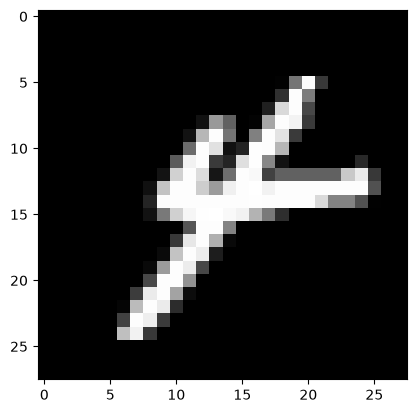

In [16]:
row=x_train[71].reshape(28,28)
plt.imshow(row, cmap='gray')


In [12]:
x_train=x_train/255.0
x_test=x_test/255.0
y_train=y_train.astype(int)
y_test=y_test.astype(int)

In [13]:
y_train_oh=np.eye(10)[y_train]
y_test_oh=np.eye(10)[y_test]

In [ ]:
np.random.seed(0)
w1=np.random.randn(784, 128)*np.sqrt(2/784)
b1=np.zeros((1, 128))
w2=np.random.randn(128, 10)*np.sqrt(2/128)
b2=np.zeros((1, 10))

(784, 128)


In [18]:
def forward(x):
    z1 = np.matmul(x, w1) + b1
    a1 = np.maximum(0, z1)
    z2 = np.matmul(a1, w2) + b2

    shifted = z2 - z2.max(axis=1, keepdims=True)
    e = np.exp(shifted)
    a2 = e / e.sum(axis=1, keepdims=True)

    return z1, a1, z2, a2

In [38]:
z1, a1, z2, a2 = forward(x_train)
compare=y_train==np.argmax(a2,axis=1)
compare.mean()

np.float64(0.11362433862433863)

In [39]:
def loss(a2, y):
    return -np.mean(np.sum(y * np.log(a2 + 1e-9), axis=1))

In [78]:
def backward(x, y, z1, a1, z2, a2):
    dz2 = (a2 - y) / len(y)
    dw2 = np.matmul(a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = np.matmul(dz2, w2.T)
    dz1 = da1 * (z1 > 0)
    dw1 = np.matmul(x.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dw1, db1, dw2, db2

In [79]:
forward(x_train[:64])
backward(x_train[:64], y_train_oh[:64], *forward(x_train[:64]))

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(784, 128)),
 array([[-0.00184603,  0.00590861, -0.00202894,  0.0335684 , -0.00307638,
         -0.0018334 , -0.02306149,  0.01890418,  0.00187639, -0.00608204,
         -0.00287761,  0.00118421,  0.00049084,  0.02961371, -0.00203953,
         -0.00521825,  0.01957782,  0.01026189,  0.01721624,  0.00284785,
          0.00567481,  0.00347718,  0.03852789,  0.00473555,  0.02809956,
         -0.01660179,  0.00382279, -0.00258656, -0.00322511,  0.0050242 ,
          0.0086371 ,  0.00582236,  0.00588381,  0.00215667,  0.00986549,
         -0.00112321, -0.0017821 , -0.02348618, -0.00769103,  0.00471499,
          0.00137021, -0.01108227,  0.04019174, -0.01607671, -0.00653253,
          0.00522492, -0.02007073,  0.02201605,  0.01323189, -0.001